# Subscription outcome classification with SMOTENC

Predict whether each customer subscribed (`yes` or `no`) after the call, using the recorded call duration and other UCI features. Compare the same classifiers with synthetic subscriber rows generated from training data only.


In [1]:
from importlib import reload
from scripts import uci_preprocessing as preprocessing_module
from scripts import uci_preprocessing_smotenc as smotenc_module
reload(preprocessing_module)
smotenc_module = reload(smotenc_module)
load_and_preprocess_uci_smotenc = smotenc_module.load_and_preprocess_uci_smotenc
make_smotenc_model_pipeline = smotenc_module.make_smotenc_model_pipeline

N_SYNTHETIC = 5000  # Additional subscriber rows generated from training data.
data = load_and_preprocess_uci_smotenc(
    n_synthetic=N_SYNTHETIC, seed=42,
    train_size=0.6, val_size=0.2, test_size=0.2,
    include_duration=True,
)
(
    X_train, X_val, X_test,
    y_train, y_val, y_test,
    X_train_processed, X_val_processed, X_test_processed,
    preprocessor, feature_names,
) = data.base
X_train_smotenc, y_train_smotenc = data.X_train_smotenc, data.y_train_smotenc
assert "duration" in X_train.columns

print("Split sizes:", {"train": len(X_train), "validation": len(X_val), "test": len(X_test)})
print("Original training counts:", y_train.value_counts().sort_index().to_dict())
print("SMOTENC training counts:", y_train_smotenc.value_counts().sort_index().to_dict())
print("Synthetic subscriber rows:", len(y_train_smotenc) - len(y_train))
print("Validation/test counts (unchanged):", y_val.value_counts().sort_index().to_dict(), y_test.value_counts().sort_index().to_dict())


Split sizes: {'train': 27126, 'validation': 9042, 'test': 9043}
Original training counts: {0: 23953, 1: 3173}
SMOTENC training counts: {0: 23953, 1: 8173}
Synthetic subscriber rows: 5000
Validation/test counts (unchanged): {0: 7984, 1: 1058} {0: 7985, 1: 1058}


## Training and validation

Compare eight classifiers using three stratified training folds. Each fold fits its own preprocessing; the SMOTENC notebook also generates synthetic rows only within that fold's training portion. Evaluate F1, accuracy, precision, recall, and PR-AUC. Select the model with the highest PR-AUC on the validation split, then evaluate it once on the untouched test split. The classification metrics use a 0.5 probability cutoff.


In [2]:
import pandas as pd
pd.options.display.float_format = "{:.3f}".format
import lightgbm as lgb
import xgboost as xgb
from catboost import CatBoostClassifier
from sklearn.base import clone
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier, StackingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score, auc, f1_score, precision_recall_curve,
    precision_score, recall_score,
)
from sklearn.model_selection import StratifiedKFold, cross_validate

SEED = 42
CV_FOLDS = 3
cv = StratifiedKFold(n_splits=CV_FOLDS, shuffle=True, random_state=SEED)

models = {
    "Logistic regression": LogisticRegression(max_iter=1000, random_state=SEED),
    "Decision tree": DecisionTreeClassifier(random_state=SEED),
    "Random forest": RandomForestClassifier(n_estimators=100, n_jobs=2, random_state=SEED),
    "Gradient boosting": GradientBoostingClassifier(random_state=SEED),
    "XGBoost": xgb.XGBClassifier(n_estimators=150, n_jobs=2, random_state=SEED),
    "LightGBM": lgb.LGBMClassifier(n_estimators=150, verbosity=-1, n_jobs=2, random_state=SEED),
    "CatBoost": CatBoostClassifier(
        iterations=200, thread_count=2, verbose=0, random_seed=SEED,
        allow_writing_files=False,
    ),
}
models["Stacking ensemble"] = StackingClassifier(
    estimators=[
        ("logistic", make_smotenc_model_pipeline(
            models["Logistic regression"], preprocessor, X_train, data.smotenc_ratio, SEED,
        )),
        ("forest", make_smotenc_model_pipeline(
            models["Random forest"], preprocessor, X_train, data.smotenc_ratio, SEED,
        )),
        ("lightgbm", make_smotenc_model_pipeline(
            models["LightGBM"], preprocessor, X_train, data.smotenc_ratio, SEED,
        )),
    ],
    final_estimator=LogisticRegression(max_iter=1000, random_state=SEED),
    stack_method="predict_proba", cv=3, n_jobs=1,
)

def pr_auc_score(y_true, probabilities):
    precision, recall, _ = precision_recall_curve(y_true, probabilities)
    return auc(recall, precision)

def metric_row(y_true, probabilities):
    predictions = (probabilities >= 0.5).astype(int)
    return {
        "f1": f1_score(y_true, predictions, zero_division=0),
        "accuracy": accuracy_score(y_true, predictions),
        "precision": precision_score(y_true, predictions, zero_division=0),
        "recall": recall_score(y_true, predictions, zero_division=0),
        "pr_auc": pr_auc_score(y_true, probabilities),
    }

def pr_auc_scorer(estimator, X, y_true):
    return pr_auc_score(y_true, estimator.predict_proba(X)[:, 1])

scoring = {
    "f1": "f1", "accuracy": "accuracy", "precision": "precision",
    "recall": "recall", "pr_auc": pr_auc_scorer,
}
cv_rows = []
validation_rows = []
fitted_models = {}
for name, estimator in models.items():
    pipeline = (
        clone(estimator) if name == "Stacking ensemble" else
        make_smotenc_model_pipeline(estimator, preprocessor, X_train, data.smotenc_ratio, SEED)
    )
    scores = cross_validate(pipeline, X_train, y_train, cv=cv, scoring=scoring, n_jobs=1)
    cv_rows.append({
        "model": name,
        **{f"{metric}_mean": scores[f"test_{metric}"].mean() for metric in scoring},
        **{f"{metric}_sd": scores[f"test_{metric}"].std(ddof=1) for metric in scoring},
    })
    pipeline.fit(X_train, y_train)
    fitted_models[name] = pipeline
    validation_rows.append({"model": name, **metric_row(y_val, pipeline.predict_proba(X_val)[:, 1])})
    print(f"Finished {name}")

cv_results = pd.DataFrame(cv_rows).set_index("model").sort_values("pr_auc_mean", ascending=False)
validation_results = pd.DataFrame(validation_rows).set_index("model").sort_values("pr_auc", ascending=False)
print("\nThree-fold cross-validation (training split; mean ± SD):")
display(cv_results.round(3))
print("\nValidation Metrics for SMOTENC Generated Data")
display(validation_results.round(3))


Finished Logistic regression
Finished Decision tree
Finished Random forest
Finished Gradient boosting
Finished XGBoost
Finished LightGBM
Finished CatBoost
Finished Stacking ensemble

Three-fold cross-validation (training split; mean ± SD):


,f1_mean,accuracy_mean,precision_mean,recall_mean,pr_auc_mean,f1_sd,accuracy_sd,precision_sd,recall_sd,pr_auc_sd
model,,,,,,,,,,
CatBoost,0.581,0.907,0.615,0.550,0.607,0.003,0.002,0.010,0.002,0.021
Stacking ensemble,0.531,0.905,0.628,0.461,0.607,0.002,0.001,0.011,0.003,0.014
LightGBM,0.578,0.904,0.596,0.562,0.602,0.004,0.000,0.004,0.010,0.004
Gradient boosting,0.575,0.899,0.569,0.581,0.581,0.007,0.004,0.020,0.008,0.018
XGBoost,0.557,0.900,0.579,0.537,0.578,0.011,0.002,0.006,0.016,0.015
Random forest,0.543,0.899,0.578,0.513,0.577,0.009,0.001,0.009,0.023,0.013
Logistic regression,0.557,0.894,0.543,0.571,0.538,0.012,0.003,0.012,0.013,0.023
Decision tree,0.480,0.866,0.440,0.528,0.512,0.009,0.004,0.012,0.017,0.009



Validation Metrics for SMOTENC Generated Data


,f1,accuracy,precision,recall,pr_auc
model,,,,,
Stacking ensemble,0.554,0.909,0.647,0.484,0.618
CatBoost,0.599,0.912,0.639,0.563,0.618
LightGBM,0.605,0.910,0.621,0.591,0.608
Random forest,0.568,0.902,0.589,0.548,0.593
XGBoost,0.575,0.902,0.586,0.564,0.584
Gradient boosting,0.573,0.899,0.566,0.580,0.565
Logistic regression,0.573,0.898,0.561,0.586,0.536
Decision tree,0.465,0.868,0.441,0.491,0.496


In [3]:
display(validation_results.round(3))


,f1,accuracy,precision,recall,pr_auc
model,,,,,
Stacking ensemble,0.554,0.909,0.647,0.484,0.618
CatBoost,0.599,0.912,0.639,0.563,0.618
LightGBM,0.605,0.910,0.621,0.591,0.608
Random forest,0.568,0.902,0.589,0.548,0.593
XGBoost,0.575,0.902,0.586,0.564,0.584
Gradient boosting,0.573,0.899,0.566,0.580,0.565
Logistic regression,0.573,0.898,0.561,0.586,0.536
Decision tree,0.465,0.868,0.441,0.491,0.496


## Selected model: held-out test evaluation

Select by validation PR-AUC and report final performance on the unchanged test data.


In [4]:
best_model_name = validation_results.index[0]
best_model = fitted_models[best_model_name]
test_results = pd.DataFrame(
    [metric_row(y_test, best_model.predict_proba(X_test)[:, 1])],
    index=[best_model_name],
)
print("Selected model:", best_model_name)
print("Held-out test metrics:")
display(test_results.round(3))

from sklearn.metrics import confusion_matrix

test_probabilities = best_model.predict_proba(X_test)[:, 1]
test_predictions = (test_probabilities >= 0.5).astype(int)
test_confusion = pd.DataFrame(
    confusion_matrix(y_test, test_predictions),
    index=["Actual no", "Actual yes"],
    columns=["Predicted no", "Predicted yes"],
)
print("Test confusion matrix (customer counts):")
display(test_confusion)


Selected model: Stacking ensemble
Held-out test metrics:


,f1,accuracy,precision,recall,pr_auc
Stacking ensemble,0.552,0.908,0.637,0.487,0.636


Test confusion matrix (customer counts):


,Predicted no,Predicted yes
Actual no,7692,293
Actual yes,543,515


## Results at a glance

The first chart compares PR-AUC across models; the second shows validation precision and recall at the 0.5 cutoff.


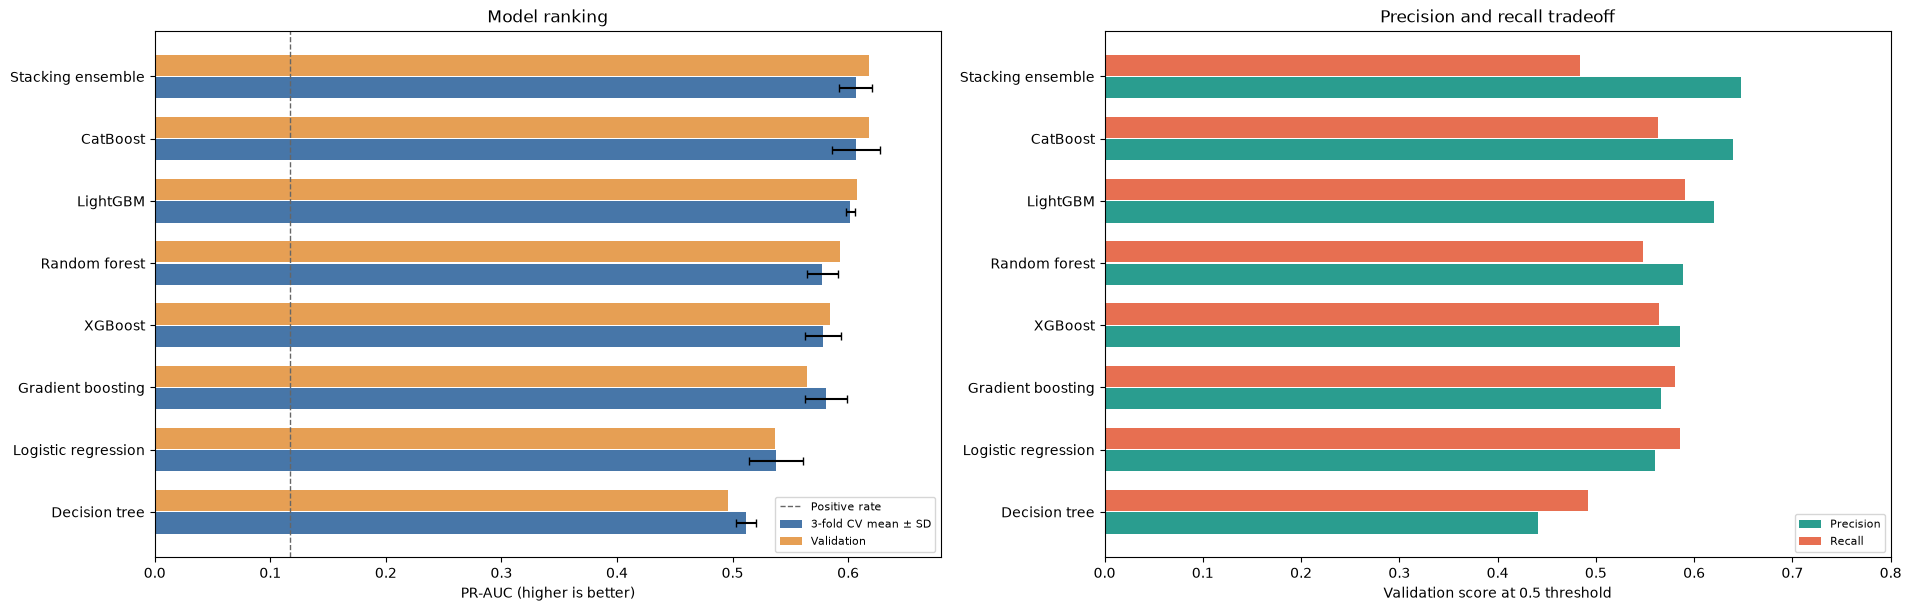

In [5]:
import matplotlib.pyplot as plt
import numpy as np

order = validation_results.index[::-1]
positions = np.arange(len(order))
fig, axes = plt.subplots(1, 2, figsize=(19, 6), layout="constrained")

# PR-AUC is the primary ranking metric for this imbalanced target.
axes[0].barh(positions - 0.18, cv_results.loc[order, "pr_auc_mean"],
             height=0.34, xerr=cv_results.loc[order, "pr_auc_sd"],
             capsize=3, label="3-fold CV mean ± SD", color="#4776A8")
axes[0].barh(positions + 0.18, validation_results.loc[order, "pr_auc"],
             height=0.34, label="Validation", color="#E69F54")
axes[0].axvline(y_train.mean(), color="#666666", linestyle="--", linewidth=1,
                label="Positive rate")
axes[0].set_yticks(positions, order)
axes[0].set_xlim(0, max(0.55, validation_results["pr_auc"].max() * 1.10))
axes[0].set_xlabel("PR-AUC (higher is better)")
axes[0].set_title("Model ranking")
axes[0].legend(fontsize=8, loc="lower right")

axes[1].barh(positions - 0.18, validation_results.loc[order, "precision"],
             height=0.34, label="Precision", color="#2A9D8F")
axes[1].barh(positions + 0.18, validation_results.loc[order, "recall"],
             height=0.34, label="Recall", color="#E76F51")
axes[1].set_yticks(positions, order)
axes[1].set_xlim(0, 0.8)
axes[1].set_xlabel("Validation score at 0.5 threshold")
axes[1].set_title("Precision and recall tradeoff")
axes[1].legend(fontsize=8, loc="lower right")

plt.show()


## More ways to read the results

The validation charts compare F1 and accuracy across all eight models. The dashed accuracy line is the score from always predicting the majority class. The test charts show how the selected model trades precision against recall as the cutoff changes, and how many subscribers and non-subscribers it classifies correctly at the 0.5 cutoff. The test set is used only for this final evaluation.


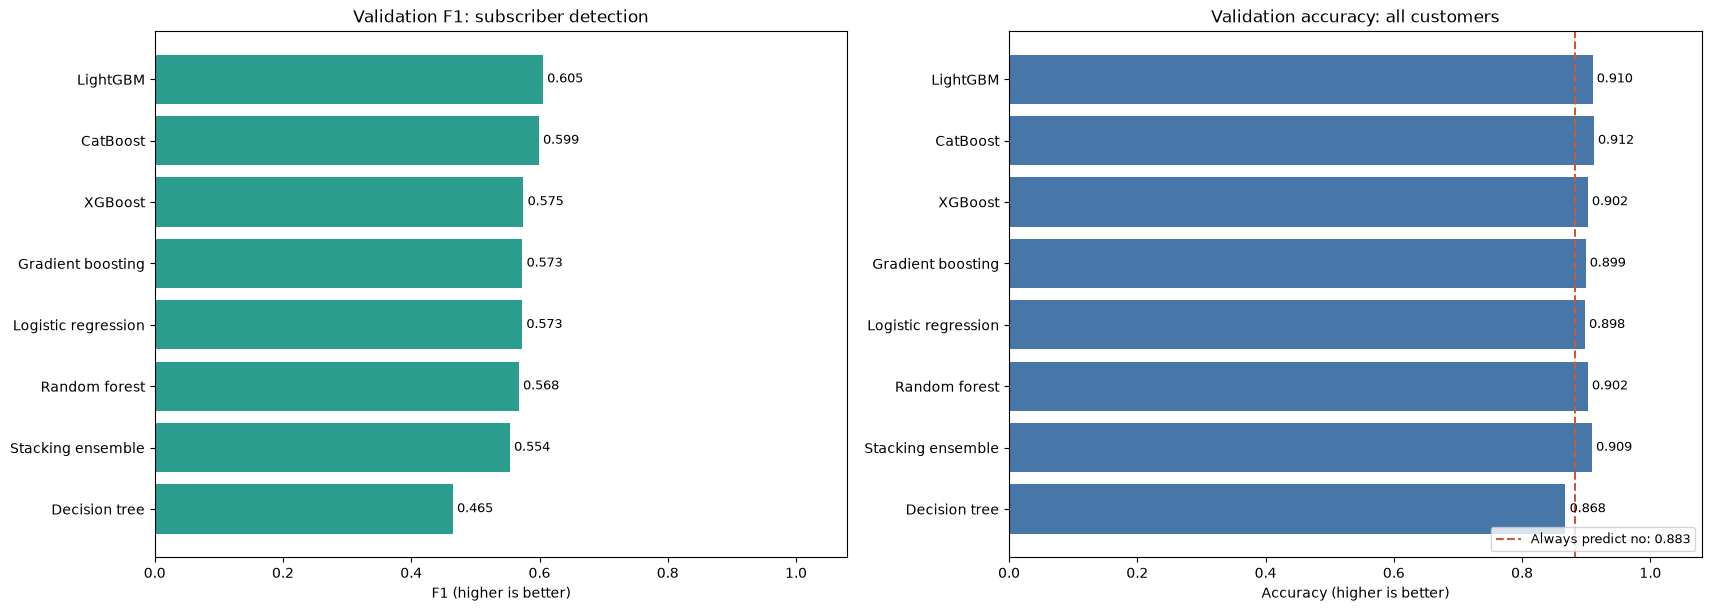

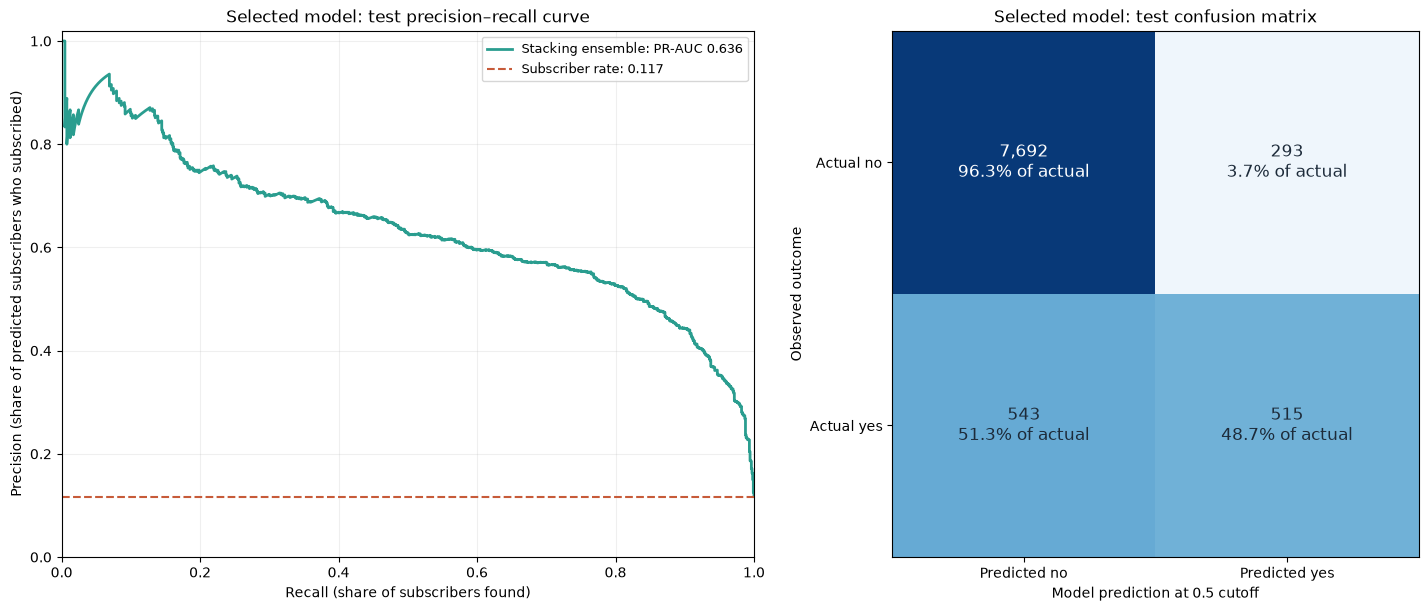

In [6]:
from sklearn.metrics import precision_recall_curve

order = validation_results.sort_values("f1").index
fig, axes = plt.subplots(1, 2, figsize=(17, 6), layout="constrained")

for ax, metric, color, title in [
    (axes[0], "f1", "#2A9D8F", "Validation F1: subscriber detection"),
    (axes[1], "accuracy", "#4776A8", "Validation accuracy: all customers"),
]:
    values = validation_results.loc[order, metric]
    bars = ax.barh(order, values, color=color)
    ax.bar_label(bars, fmt="%.3f", padding=3, fontsize=9)
    ax.set_xlim(0, 1.08)
    ax.set_xlabel(f"{metric.upper() if metric == 'f1' else metric.title()} (higher is better)")
    ax.set_title(title)
axes[1].axvline(max(y_val.mean(), 1 - y_val.mean()), color="#C75B39",
                linestyle="--", linewidth=1.5,
                label=f"Always predict no: {1 - y_val.mean():.3f}")
axes[1].legend(loc="lower right", fontsize=9)
plt.show()

precision_curve, recall_curve, _ = precision_recall_curve(y_test, test_probabilities)
fig, axes = plt.subplots(1, 2, figsize=(15, 6), layout="constrained")

axes[0].plot(recall_curve, precision_curve, color="#2A9D8F", linewidth=2,
             label=f"{best_model_name}: PR-AUC {test_results.loc[best_model_name, 'pr_auc']:.3f}")
axes[0].axhline(y_test.mean(), color="#C75B39", linestyle="--", linewidth=1.5,
                label=f"Subscriber rate: {y_test.mean():.3f}")
axes[0].set(xlim=(0, 1), ylim=(0, 1.02), xlabel="Recall (share of subscribers found)",
            ylabel="Precision (share of predicted subscribers who subscribed)",
            title="Selected model: test precision–recall curve")
axes[0].legend(loc="upper right", fontsize=9)
axes[0].grid(alpha=0.2)

counts = test_confusion.to_numpy()
row_shares = counts / counts.sum(axis=1, keepdims=True)
axes[1].imshow(row_shares, cmap="Blues", vmin=0, vmax=1)
for row in range(2):
    for col in range(2):
        axes[1].text(col, row, f"{counts[row, col]:,}\n{row_shares[row, col]:.1%} of actual",
                     ha="center", va="center", fontsize=12,
                     color="white" if row_shares[row, col] > 0.55 else "#1D2B3A")
axes[1].set_xticks([0, 1], ["Predicted no", "Predicted yes"])
axes[1].set_yticks([0, 1], ["Actual no", "Actual yes"])
axes[1].set_xlabel("Model prediction at 0.5 cutoff")
axes[1].set_ylabel("Observed outcome")
axes[1].set_title("Selected model: test confusion matrix")
plt.show()


## Interpretation

**Evaluation and predictability.** Stacking had the highest validation PR-AUC. On the untouched test split it scored **0.636 PR-AUC, 0.552 F1, and 0.908 accuracy**. At the 0.5 cutoff, it identified **515 of 1,058 subscribers** (recall **0.487**) and incorrectly flagged **293 non-subscribers** (precision **0.637**). Accuracy looks high partly because most customers did not subscribe; recall and PR-AUC are more informative about the subscriber class.

**Business meaning.** The full call duration is known after the interaction. This model can help analyze completed-call records or prioritize records for review, but it cannot use that duration to decide whom to call beforehand. A business benefit would require a defined action, its cost, and a prospective evaluation.

**Synthetic generation and GAN.** With 5,000 SMOTENC-generated subscriber rows, this model found **13 more subscribers** than the baseline at the same cutoff, but produced **44 more false positives** and a lower PR-AUC (**0.636 versus 0.650**). SMOTENC creates examples from nearby training rows; a conditional tabular GAN might capture richer relationships across mixed feature types and generate more diverse subscriber examples. It could also learn noise or overfit, so improvement must be demonstrated on untouched validation and test data. [CTGAN paper](https://papers.neurips.cc/paper_files/paper/2019/hash/254ed7d2de3b23ab10936522dd547b78-Abstract.html)


## Before and after SMOTENC

Compare the **same stacking architecture** trained on the original training rows and on the SMOTENC training pipeline. Both models are evaluated on the same untouched test customers at the same 0.5 cutoff. This isolates the effect of adding synthetic subscriber rows; the other model rankings above use their own validation scores.


,f1,accuracy,precision,recall,pr_auc
Before SMOTENC,0.555,0.911,0.668,0.474,0.650
After SMOTENC,0.552,0.908,0.637,0.487,0.636


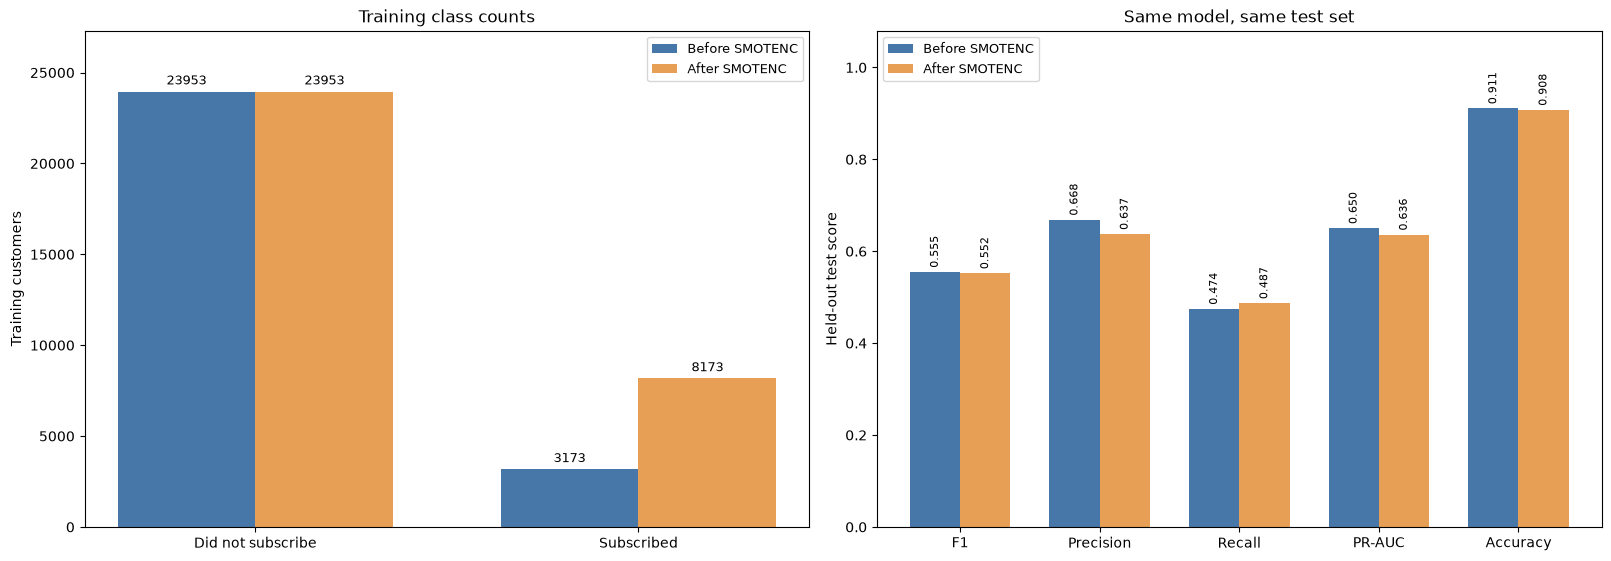

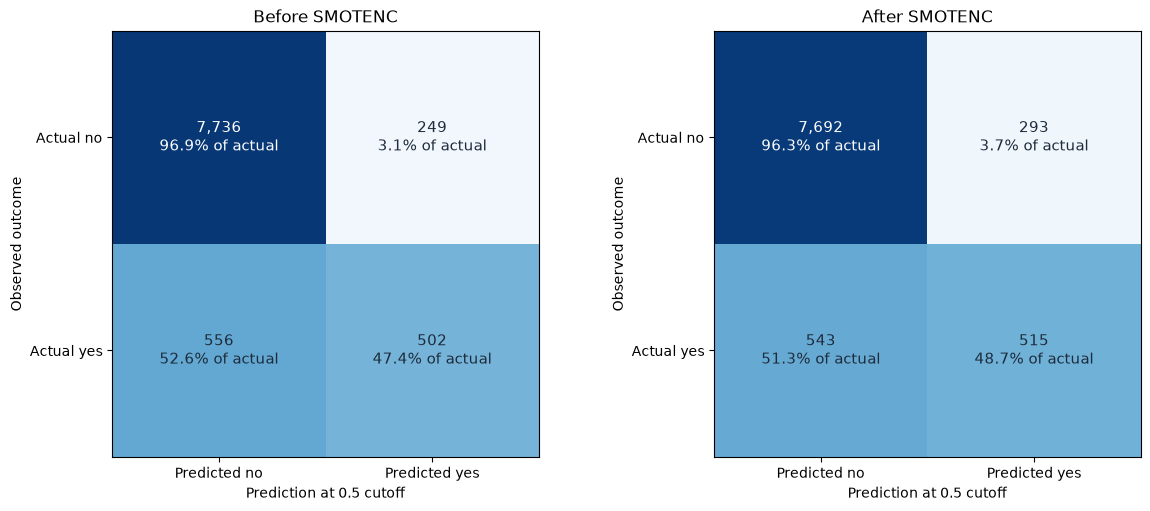

In [7]:
from sklearn.pipeline import make_pipeline
from sklearn.metrics import confusion_matrix

baseline_stack = StackingClassifier(
    estimators=[
        ("logistic", clone(models["Logistic regression"])),
        ("forest", clone(models["Random forest"])),
        ("lightgbm", clone(models["LightGBM"])),
    ],
    final_estimator=LogisticRegression(max_iter=1000, random_state=SEED),
    stack_method="predict_proba", cv=3, n_jobs=1,
)
baseline_stack = make_pipeline(clone(preprocessor), baseline_stack)
baseline_stack.fit(X_train, y_train)
smotenc_stack = fitted_models["Stacking ensemble"]

before_probabilities = baseline_stack.predict_proba(X_test)[:, 1]
after_probabilities = smotenc_stack.predict_proba(X_test)[:, 1]
comparison_results = pd.DataFrame.from_dict({
    "Before SMOTENC": metric_row(y_test, before_probabilities),
    "After SMOTENC": metric_row(y_test, after_probabilities),
}, orient="index")
display(comparison_results.round(3))

fig, axes = plt.subplots(1, 2, figsize=(16, 5.5), layout="constrained")
training_counts = pd.DataFrame({
    "Before SMOTENC": y_train.value_counts().reindex([0, 1], fill_value=0),
    "After SMOTENC": y_train_smotenc.value_counts().reindex([0, 1], fill_value=0),
})
locations = np.arange(2)
width = 0.36
colors = {"Before SMOTENC": "#4776A8", "After SMOTENC": "#E69F54"}
for offset, stage in [(-width / 2, "Before SMOTENC"), (width / 2, "After SMOTENC")]:
    bars = axes[0].bar(locations + offset, training_counts[stage], width,
                       label=stage, color=colors[stage])
    axes[0].bar_label(bars, fmt="%d", padding=3, fontsize=9)
axes[0].set_xticks(locations, ["Did not subscribe", "Subscribed"])
axes[0].set_ylabel("Training customers")
axes[0].set_title("Training class counts")
axes[0].set_ylim(0, training_counts.to_numpy().max() * 1.14)
axes[0].legend(fontsize=9)

metric_names = ["f1", "precision", "recall", "pr_auc", "accuracy"]
metric_locations = np.arange(len(metric_names))
for offset, stage in [(-width / 2, "Before SMOTENC"), (width / 2, "After SMOTENC")]:
    bars = axes[1].bar(metric_locations + offset, comparison_results.loc[stage, metric_names],
                       width, label=stage, color=colors[stage])
    axes[1].bar_label(bars, fmt="%.3f", padding=3, fontsize=8, rotation=90)
axes[1].set_xticks(metric_locations, ["F1", "Precision", "Recall", "PR-AUC", "Accuracy"])
axes[1].set_ylim(0, 1.08)
axes[1].set_ylabel("Held-out test score")
axes[1].set_title("Same model, same test set")
axes[1].legend(fontsize=9, loc="upper left")
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 5), layout="constrained")
for ax, stage, probabilities in zip(
    axes,
    ("Before SMOTENC", "After SMOTENC"),
    (before_probabilities, after_probabilities),
):
    counts = confusion_matrix(y_test, probabilities >= 0.5)
    row_shares = counts / counts.sum(axis=1, keepdims=True)
    ax.imshow(row_shares, cmap="Blues", vmin=0, vmax=1)
    for row in range(2):
        for col in range(2):
            ax.text(col, row, f"{counts[row, col]:,}\n{row_shares[row, col]:.1%} of actual",
                    ha="center", va="center", fontsize=11,
                    color="white" if row_shares[row, col] > 0.55 else "#1D2B3A")
    ax.set_xticks([0, 1], ["Predicted no", "Predicted yes"])
    ax.set_yticks([0, 1], ["Actual no", "Actual yes"])
    ax.set_xlabel("Prediction at 0.5 cutoff")
    ax.set_ylabel("Observed outcome")
    ax.set_title(stage)
plt.show()
